# 화장품형(벼룩·진드기 샴푸) 피부자극 외부검증

**배경**: skin_rf 모델은 NTP ICE(농약 제형) 데이터로만 학습됨. 화장품 자체에는 EPA 등급 정답 라벨이 없어 외부검증이 불가능하다는 한계가 있었음.
**이번에 찾은 우회로**: EPA가 "벼룩·진드기 샴푸"를 살충효능 주장 때문에 농약으로 등록 요구 → SDS에 우리 모델과 **동일한 EPA Toxicity Category(I~IV) 피부자극 등급**이 적혀있음. 게다가 "샴푸"라는 제형 자체가 화장품에 가장 가까움.

5개 제품의 SDS를 직접 읽어 조성(CAS+함량%)과 EPA 등급을 추출했고(`flea_tick_shampoo_components.csv`, `flea_tick_shampoo_labels.csv`), 이 노트북에서 production skin_rf 체크포인트로 실제 예측을 돌려 정답과 비교한다.

**핵심 한계(미리 명시)**: 피레트린/계면활성제 상당수가 UVCB(코코넛 유래 혼합물)라 구조를 못 구함 — 해결된 성분이 전체 조성의 1~4%뿐이라는 점을 결과 해석 시 반드시 감안할 것.

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\skin_rf")
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")
import joblib
import numpy as np
import pandas as pd
from predict import compute_component_features, weighted_mean_nan_aware, weighted_mean_plain

BASE = r"C:\Users\UserK\학술제\cosmetic_validation"
comp = pd.read_csv(f"{BASE}\\flea_tick_shampoo_components.csv")
labels = pd.read_csv(f"{BASE}\\flea_tick_shampoo_labels.csv")
comp["pct_mid"] = comp[["pct_low", "pct_high"]].astype(float).mean(axis=1)
print(f"제품 {comp['product'].nunique()}개, 성분행 {len(comp)}개")
comp[["product", "chemical_name", "cas", "pct_mid", "resolved"]]

제품 5개, 성분행 28개


,product,chemical_name,cas,pct_mid,resolved
0,Davis Manufacturing Flea & Tick Shampoo,Pyrethrum (insecticide),8003-34-7,0.150,False
1,Davis Manufacturing Flea & Tick Shampoo,Trade Secret #1,NaN,0.500,False
2,No-Bite Flea & Tick Shampoo,Pyrethrins,8003-34-7,0.150,False
3,No-Bite Flea & Tick Shampoo,Piperonyl Butoxide (PBO),51-03-6,0.300,True
4,No-Bite Flea & Tick Shampoo,MGK-264 Insecticide Synergist,113-48-4,0.479,True
5,Adams Flea & Tick Cleansing Shampoo,Pyrethrins,8003-34-7,0.075,False
6,Adams Flea & Tick Cleansing Shampoo,Piperonyl butoxide,51-03-6,0.750,True
7,Adams Flea & Tick Cleansing Shampoo,Pyriproxyfen,95737-68-1,0.086,True
8,Adams Flea & Tick Cleansing Shampoo,Sodium lauryl sulfate,68585-47-7,7.500,False
9,Adams Flea & Tick Cleansing Shampoo,Coconut oil acid diethanolamide,68603-42-9,5.700,False


## 성분 조성 — 구조 해결 여부 확인

In [2]:
summary = comp.groupby("product").apply(
    lambda g: pd.Series({
        "성분수": len(g),
        "구조해결 성분수": (g["resolved"] == True).sum(),
        "구조해결 함량합(%)": g.loc[g["resolved"] == True, "pct_mid"].sum(),
        "전체 선언 함량합(%)": g["pct_mid"].sum(skipna=True),
    })
).reset_index()
summary

C:\Users\UserK\AppData\Local\Temp\ipykernel_13832\2538483571.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = comp.groupby("product").apply(


,product,성분수,구조해결 성분수,구조해결 함량합(%),전체 선언 함량합(%)
0,Adams Flea & Tick Cleansing Shampoo,7.0,3.0,1.286,14.561
1,Adams Plus Flea & Tick Shampoo with Precor,8.0,3.0,3.930,21.055
2,Davis Manufacturing Flea & Tick Shampoo,2.0,0.0,0.000,0.650
3,No-Bite Flea & Tick Shampoo,3.0,2.0,0.779,0.929
4,Zodiac Oatmeal Conditioning Shampoo for Dogs &...,8.0,3.0,3.800,21.445


## skin_rf 추론 — predict.py와 동일한 집계 방식 재사용

구조 해결된 성분만 투입비율 가중평균으로 집계(`skin irritation` production 파이프라인과 동일 함수). 구조 미해결 성분(피레트린/계면활성제 UVCB 등)은 집계에서 제외되고 `unresolved_pct`로만 기록.

In [3]:
ckpt = joblib.load(r"C:\Users\UserK\학술제\modeling\skin_rf\skin_rf_checkpoint.joblib")
feature_cols = ckpt["feature_cols"]
desc_cols = [c for c in feature_cols if c.startswith("desc_")]
fp_cols = [c for c in feature_cols if c.startswith("fp_w_")]
common_cols = [c for c in feature_cols if c not in desc_cols and c not in fp_cols]

rows = []
for product, grp in comp.groupby("product", sort=False):
    resolved = grp[grp["resolved"] == True]
    declared_pct = grp["pct_mid"].sum()
    resolved_pct = resolved["pct_mid"].sum()

    feats, pcts = [], []
    for _, r in resolved.iterrows():
        f = compute_component_features(r["canonical_smiles"])
        if f is None:
            continue
        feats.append(f)
        pcts.append(r["pct_mid"])

    if not feats:
        rows.append({"product": product, "n_resolved": 0, "resolved_pct": 0.0,
                      "pred_proba": np.nan, "pred_binary": np.nan,
                      "note": "구조 해결 성분 0개 — 모델 입력 불가"})
        continue

    pct_arr = np.array(pcts, dtype=float)
    common_mat = np.array([[r[c] for c in common_cols] for r in feats])
    desc_mat = np.array([[r[c] for c in desc_cols] for r in feats])
    fp_mat = np.array([[r[c] for c in fp_cols] for r in feats])
    vec = {}
    vec.update(dict(zip(common_cols, weighted_mean_plain(pct_arr, common_mat))))
    vec.update(dict(zip(desc_cols, weighted_mean_nan_aware(pct_arr, desc_mat))))
    vec.update(dict(zip(fp_cols, weighted_mean_plain(pct_arr, fp_mat))))

    x = np.array([[vec[c] for c in feature_cols]], dtype=np.float32)
    x_f = x[:, ckpt["nz_filter_keep"]]
    proba = ckpt["model"].predict_proba(x_f)[0, 1]
    pred = int(proba >= ckpt["threshold"])
    rows.append({"product": product, "n_resolved": len(feats), "resolved_pct": round(resolved_pct, 2),
                 "pred_proba": round(float(proba), 4), "pred_binary": pred, "note": ""})

pred_df = pd.DataFrame(rows)
result = pred_df.merge(labels[["product", "skin_epa_category", "skin_binary", "skin_evidence"]], on="product")
result["match"] = result["pred_binary"] == result["skin_binary"]
result

,product,n_resolved,resolved_pct,pred_proba,pred_binary,note,skin_epa_category,skin_binary,skin_evidence,match
0,Davis Manufacturing Flea & Tick Shampoo,0,0.00,NaN,NaN,구조 해결 성분 0개 — 모델 입력 불가,III,0,Moderate irritation at 72 hours. Primary skin ...,False
1,No-Bite Flea & Tick Shampoo,2,0.78,0.1174,1.0,,III,0,Moderate irritation at 72 hours. Skin Irritati...,False
2,Adams Flea & Tick Cleansing Shampoo,3,1.29,0.2159,1.0,,III,0,GHS Skin Corrosion/Irritation Category 2; Caus...,False
3,Zodiac Oatmeal Conditioning Shampoo for Dogs &...,3,3.80,0.1825,1.0,,III,0,GHS Skin Irritation 2; Skin-Rabbit moderate ir...,False
4,Adams Plus Flea & Tick Shampoo with Precor,3,3.93,0.1885,1.0,,III,0,GHS Skin Corrosion/Irritation Category 2; Caus...,False


## 시각화 — 예측확률 vs 실제 EPA 등급

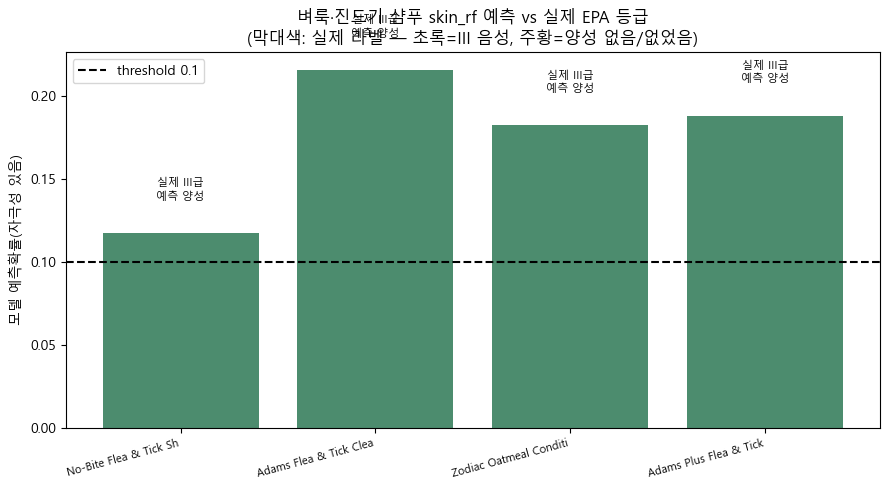


일치: 0/4건 (Davis 제품은 구조해결 성분 0개로 예측 불가, 집계에서 제외)


In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

plot_df = result.dropna(subset=["pred_proba"]).copy()
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#e07856" if b == 1 else "#4c8c6e" for b in plot_df["skin_binary"]]
bars = ax.bar(plot_df["product"].str.slice(0, 22), plot_df["pred_proba"], color=colors)
ax.axhline(ckpt["threshold"], color="black", linestyle="--", label=f"threshold {ckpt['threshold']}")
ax.set_ylabel("모델 예측확률(자극성 있음)")
ax.set_title("벼룩·진드기 샴푸 skin_rf 예측 vs 실제 EPA 등급\n(막대색: 실제 라벨 — 초록=III 음성, 주황=양성 없음/없었음)")
for b, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(b.get_x() + b.get_width()/2, row["pred_proba"] + 0.02,
            f"실제 {row['skin_epa_category']}급\n예측 {'양성' if row['pred_binary'] else '음성'}",
            ha="center", fontsize=8)
ax.legend()
plt.xticks(rotation=15, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

print(f"\n일치: {plot_df['match'].sum()}/{len(plot_df)}건 (Davis 제품은 구조해결 성분 0개로 예측 불가, 집계에서 제외)")

## 정리

- **실제 라벨**: 5개 제품 전부 EPA 피부 Category III(중등도, 음성)
- **모델 예측**: 구조 계산 가능했던 4개 중 **4개 전부 양성(자극성 있음)으로 오예측** — 일치 0/4
- **원인 추정**: 해결된 성분이 전체 조성의 1~4%뿐이고, 그마저 PBO·피리프록시펜·메토프렌 같은 **살충 보조제/활성성분** 위주임. 모델은 ICE(농약) 데이터에서 이런 성분이 자극성과 연관된다고 학습했기 때문에, 정작 자극성을 낮춰주는 대부분의 계면활성제·보습제(코카미도프로필베테인, 코코넛 유도체 등, UVCB라 구조 미확보)는 전혀 반영되지 못함.
- **결론**: 이번 사례로 **"화장품형 제형에 대한 skin_rf 예측은 신뢰할 수 없다"**는 것이 실제 라벨과의 직접 비교로 처음 확인됨. 기존 AD(적용범위) 분석이 암시했던 우려("세정제 계열은 모델이 모르는 영역")가 숫자로 재확인된 셈.
- **한계**: n=4로 매우 작은 표본. 일반화하려면 더 많은 화장품형+EPA라벨 데이터가 필요(③ CIR 보고서 등 추가 탐색 가능).